<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%208/DS_Practice_SupervisedRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_SupervisedRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: Supervised Learning: Regression
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Understand the **regression workflow** and the metrics **MAE, RMSE, and R²**
- Fit **linear regression** and read its coefficients and **residual diagnostics**
- Control complexity with **Ridge, Lasso, and ElasticNet** regularisation
- Recognise **overfitting** with polynomial features and compare linear vs non-linear models
- Interpret models with **permutation importance** and tune them inside a **Pipeline**

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** A regression model must be judged in the units of the target, against a baseline, and with its residuals. A good R² can still hide a model that is systematically wrong in one region.

---

## Part 0: Setup & Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.model_selection import (
    train_test_split, cross_validate, KFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    RidgeCV, LassoCV, ElasticNetCV
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Reproducible randomness ───────────────────────────────────────────
RNG = np.random.default_rng(seed=42)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [ ]:
# ── Load datasets ─────────────────────────────────────────────────────
# We use two datasets:
#   diabetes: 10 baseline features, target = disease progression one year later (real data)
#   houses:   a synthetic house-price table we generate ourselves, so that we KNOW which
#             effects are real: non-linear distance effect, a duplicated feature, a useless feature.

# Diabetes dataset
# (sklearn ships these features already mean-centred and scaled; we still scale inside pipelines out of habit)
db = load_diabetes()
X_db = pd.DataFrame(db.data, columns=db.feature_names)
y_db = pd.Series(db.target, name="progression")

# Synthetic house prices (price in thousand EUR)
def make_house_data(n=600, seed=7):
    r = np.random.default_rng(seed)
    area      = np.clip(r.normal(110, 35, n), 35, 250)               # square metres
    bedrooms  = np.clip(np.round(area / 35 + r.normal(0, 0.7, n)), 1, 6)
    age       = r.uniform(0, 60, n)                                  # years
    dist      = r.gamma(2.5, 2.5, n)                                 # km to city centre
    garden    = r.binomial(1, 0.4, n)
    area_sqft = area * 10.764 + r.normal(0, 8, n)                    # near-duplicate of area_m2
    junk      = r.normal(0, 1, n)                                    # unrelated to price
    price = (30 + 2.0 * area - 0.9 * age + 140 * np.exp(-dist / 4)
             + 22 * garden + 0.004 * area ** 2 + r.normal(0, 15, n))
    X = pd.DataFrame({"area_m2": area, "area_sqft": area_sqft, "bedrooms": bedrooms,
                      "age_years": age, "dist_centre_km": dist, "has_garden": garden,
                      "random_noise": junk})
    return X, pd.Series(price, name="price_k_eur")

X_house, y_house = make_house_data()

print("=== Diabetes ===")
print(f"  Samples: {X_db.shape[0]},  Features: {X_db.shape[1]}")
print(f"  Target: mean = {y_db.mean():.1f},  std = {y_db.std():.1f},  range = [{y_db.min():.0f}, {y_db.max():.0f}]")
print()
print("=== Synthetic Houses ===")
print(f"  Samples: {X_house.shape[0]},  Features: {X_house.shape[1]}")
print(f"  Target: mean = {y_house.mean():.1f},  std = {y_house.std():.1f}  (thousand EUR)")
print()
X_db.describe().round(3)

=== Diabetes ===
  Samples: 442,  Features: 10
  Target: mean = 152.1,  std = 77.1,  range = [25, 346]

=== Synthetic Houses ===
  Samples: 600,  Features: 7
  Target: mean = 314.5,  std = 97.9  (thousand EUR)



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136


---
## Part 1: The Regression Workflow

**Supervised regression** learns a mapping from features $X$ to a **continuous number** $y$ (a price, a temperature, a score).

The workflow mirrors classification, but the metrics change:

| Metric | Formula | Units | Interpretation |
|---|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y - \hat{y} \rvert$ | same as $y$ | Typical size of an error, robust to outliers |
| **MSE** | $\frac{1}{n}\sum (y - \hat{y})^2$ | $y^2$ | Punishes large errors heavily |
| **RMSE** | $\sqrt{\text{MSE}}$ | same as $y$ | Like MAE but with extra weight on big misses |
| **R²** | $1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2}$ | unitless | Fraction of variance explained; 0 = no better than predicting the mean |

> **The baseline for regression** is the model that always predicts the **training mean**. By definition its R² is about 0. A real model must beat it, and RMSE in the original units tells you whether the improvement is useful in practice.  
> **R² can be negative** on test data: it means the model is worse than predicting the mean.

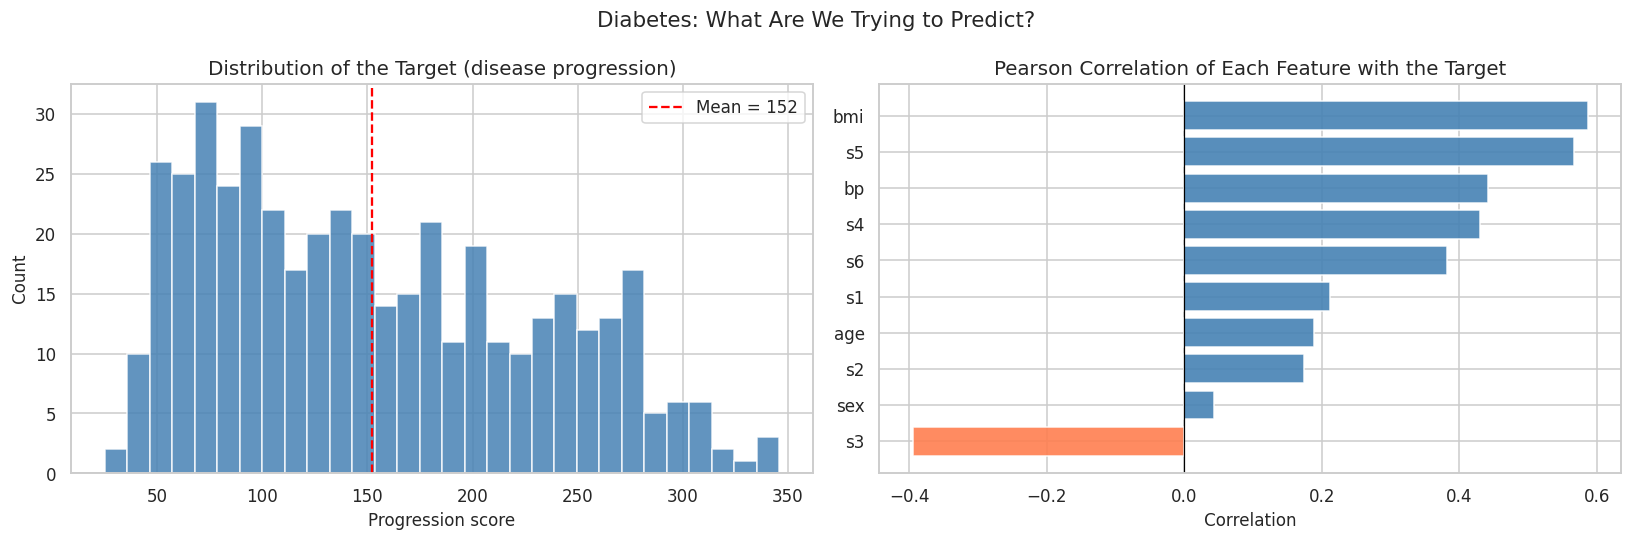

Strongest positive correlation: bmi (r = 0.59)
Strongest negative correlation: s3 (r = -0.39)


In [ ]:
# ── 1.1  Look at the target and its relationships ────────────────────

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Diabetes: What Are We Trying to Predict?", fontsize=14)

# Target distribution
axes[0].hist(y_db, bins=30, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(y_db.mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean = {y_db.mean():.0f}")
axes[0].set_title("Distribution of the Target (disease progression)")
axes[0].set_xlabel("Progression score")
axes[0].set_ylabel("Count")
axes[0].legend()

# Correlation of each feature with the target
corr_t = X_db.corrwith(y_db).sort_values()
axes[1].barh(corr_t.index, corr_t.values,
             color=["coral" if v < 0 else "steelblue" for v in corr_t.values],
             edgecolor="white", alpha=0.9)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Pearson Correlation of Each Feature with the Target")
axes[1].set_xlabel("Correlation")

plt.tight_layout()
plt.show()

print(f"Strongest positive correlation: {corr_t.idxmax()} (r = {corr_t.max():.2f})")
print(f"Strongest negative correlation: {corr_t.idxmin()} (r = {corr_t.min():.2f})")

In [ ]:
# ── 1.2  Split, define a metric helper, and fit the baseline ─────────

X_train, X_test, y_train, y_test = train_test_split(X_db, y_db, test_size=0.25, random_state=42)

def reg_metrics(model, Xte, yte):
    """Return MAE, RMSE, R2 of a fitted model on the given data."""
    pred = model.predict(Xte)
    return {"MAE":  mean_absolute_error(yte, pred),
            "RMSE": np.sqrt(mean_squared_error(yte, pred)),
            "R2":   r2_score(yte, pred)}

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_m   = reg_metrics(baseline, X_test, y_test)

print(f"Train: {X_train.shape[0]} samples   Test: {X_test.shape[0]} samples")
print(f"\nBaseline (always predict {y_train.mean():.1f}):")
print(f"  MAE  = {base_m['MAE']:.2f}")
print(f"  RMSE = {base_m['RMSE']:.2f}   <- the error to beat, in target units")
print(f"  R2   = {base_m['R2']:.4f}   <- about 0 by construction")

Train: 331 samples   Test: 111 samples

Baseline (always predict 154.3):
  MAE  = 65.53
  RMSE = 74.88   <- the error to beat, in target units
  R2   = -0.0140   <- about 0 by construction


---
## Part 2: Linear Regression

Linear regression fits $\hat{y} = b_0 + b_1 x_1 + \dots + b_p x_p$ by minimising the sum of squared residuals (**Ordinary Least Squares**).

- Each **coefficient** $b_j$ says: *holding the other features fixed, one unit more of $x_j$ changes the prediction by $b_j$*.
- If features are **standardised**, coefficients become comparable: a larger $|b_j|$ means a stronger effect per standard deviation.

**Residuals** $e = y - \hat{y}$ are the most important diagnostic. A good linear fit has residuals that look like **random noise**: no curve, no funnel shape, roughly bell-shaped.

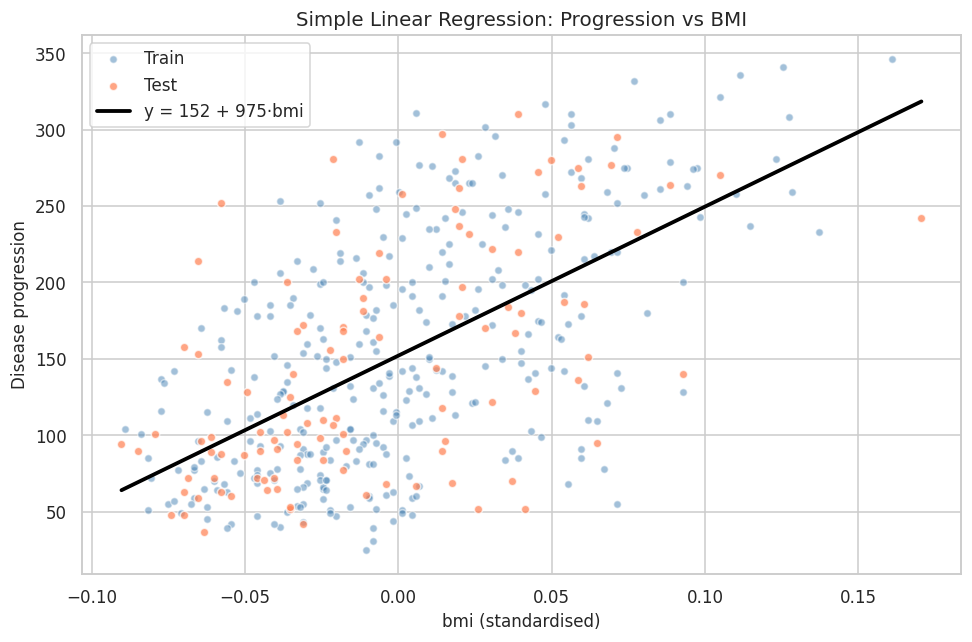

BMI-only model:  RMSE = 61.45   R2 = 0.317
Baseline:        RMSE = 74.88   R2 = -0.014


In [ ]:
# ── 2.1  Simple regression: one feature, one line ────────────────────
# Start with BMI alone so the model is easy to see.

simple = LinearRegression().fit(X_train[["bmi"]], y_train)
sm = reg_metrics(simple, X_test[["bmi"]], y_test)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_train["bmi"], y_train, alpha=0.5, s=25, color="steelblue", label="Train", edgecolors="white")
ax.scatter(X_test["bmi"],  y_test,  alpha=0.7, s=30, color="coral",     label="Test",  edgecolors="white")
xs = np.linspace(X_db["bmi"].min(), X_db["bmi"].max(), 100).reshape(-1, 1)
ax.plot(xs, simple.predict(xs), color="black", linewidth=2.5,
        label=f"y = {simple.intercept_:.0f} + {simple.coef_[0]:.0f}·bmi")
ax.set_xlabel("bmi (standardised)")
ax.set_ylabel("Disease progression")
ax.set_title("Simple Linear Regression: Progression vs BMI")
ax.legend()
plt.tight_layout()
plt.show()

print(f"BMI-only model:  RMSE = {sm['RMSE']:.2f}   R2 = {sm['R2']:.3f}")
print(f"Baseline:        RMSE = {base_m['RMSE']:.2f}   R2 = {base_m['R2']:.3f}")

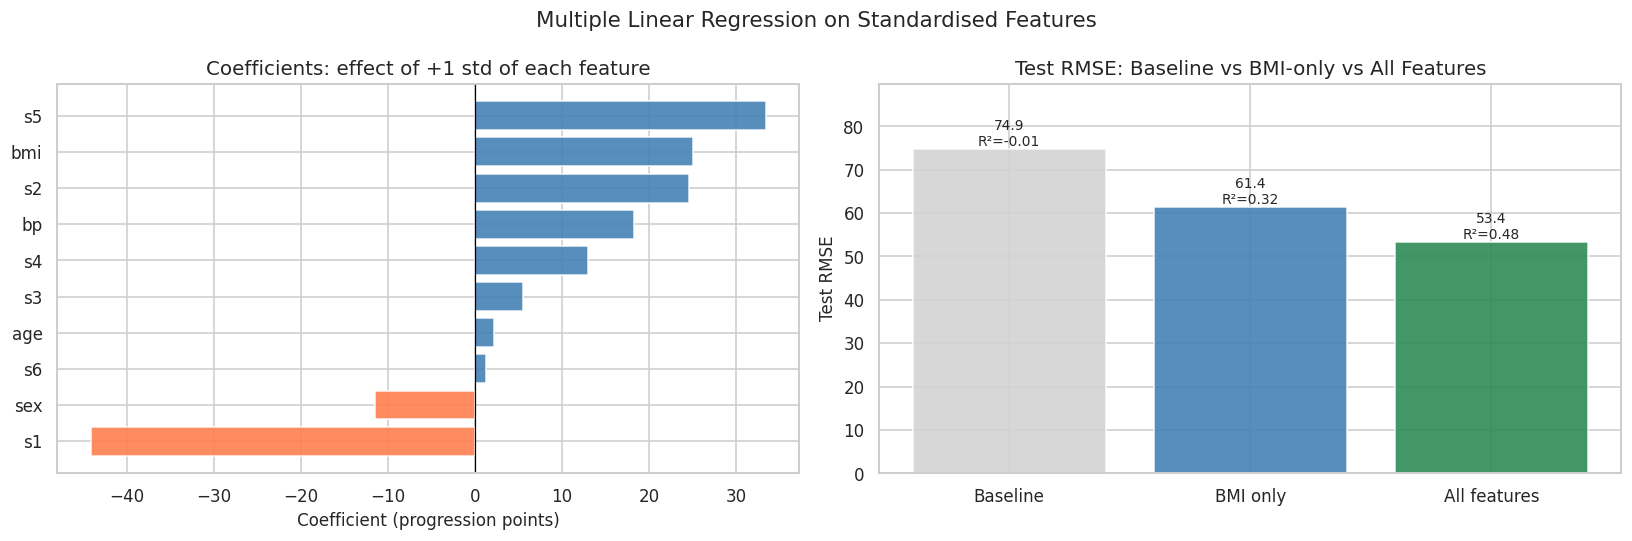

                 MAE    RMSE     R2
Baseline      65.527  74.881 -0.014
BMI only      49.805  61.446  0.317
All features  41.549  53.370  0.485

Note s1 and s2 (blood serum measurements) have large opposite coefficients: they are strongly
correlated, so OLS splits their joint effect unstably. Regularisation (Part 3) addresses exactly this.


In [ ]:
# ── 2.2  Multiple regression: all ten features ───────────────────────

ols = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ols.fit(X_train, y_train)
om = reg_metrics(ols, X_test, y_test)

coefs = pd.Series(ols.named_steps["model"].coef_, index=X_db.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Multiple Linear Regression on Standardised Features", fontsize=14)

axes[0].barh(coefs.index, coefs.values,
             color=["coral" if v < 0 else "steelblue" for v in coefs.values],
             edgecolor="white", alpha=0.9)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Coefficients: effect of +1 std of each feature")
axes[0].set_xlabel("Coefficient (progression points)")

cmp = pd.DataFrame({"Baseline": base_m, "BMI only": sm, "All features": om}).T
axes[1].bar(cmp.index, cmp["RMSE"], color=["lightgrey", "steelblue", "seagreen"], edgecolor="white", alpha=0.9)
for i, v in enumerate(cmp["RMSE"]):
    axes[1].text(i, v + 0.6, f"{v:.1f}\nR²={cmp['R2'].iloc[i]:.2f}", ha="center", fontsize=9)
axes[1].set_ylim(0, cmp["RMSE"].max() * 1.2)
axes[1].set_ylabel("Test RMSE")
axes[1].set_title("Test RMSE: Baseline vs BMI-only vs All Features")

plt.tight_layout()
plt.show()

print(cmp.round(3).to_string())
print("\nNote s1 and s2 (blood serum measurements) have large opposite coefficients: they are strongly")
print("correlated, so OLS splits their joint effect unstably. Regularisation (Part 3) addresses exactly this.")

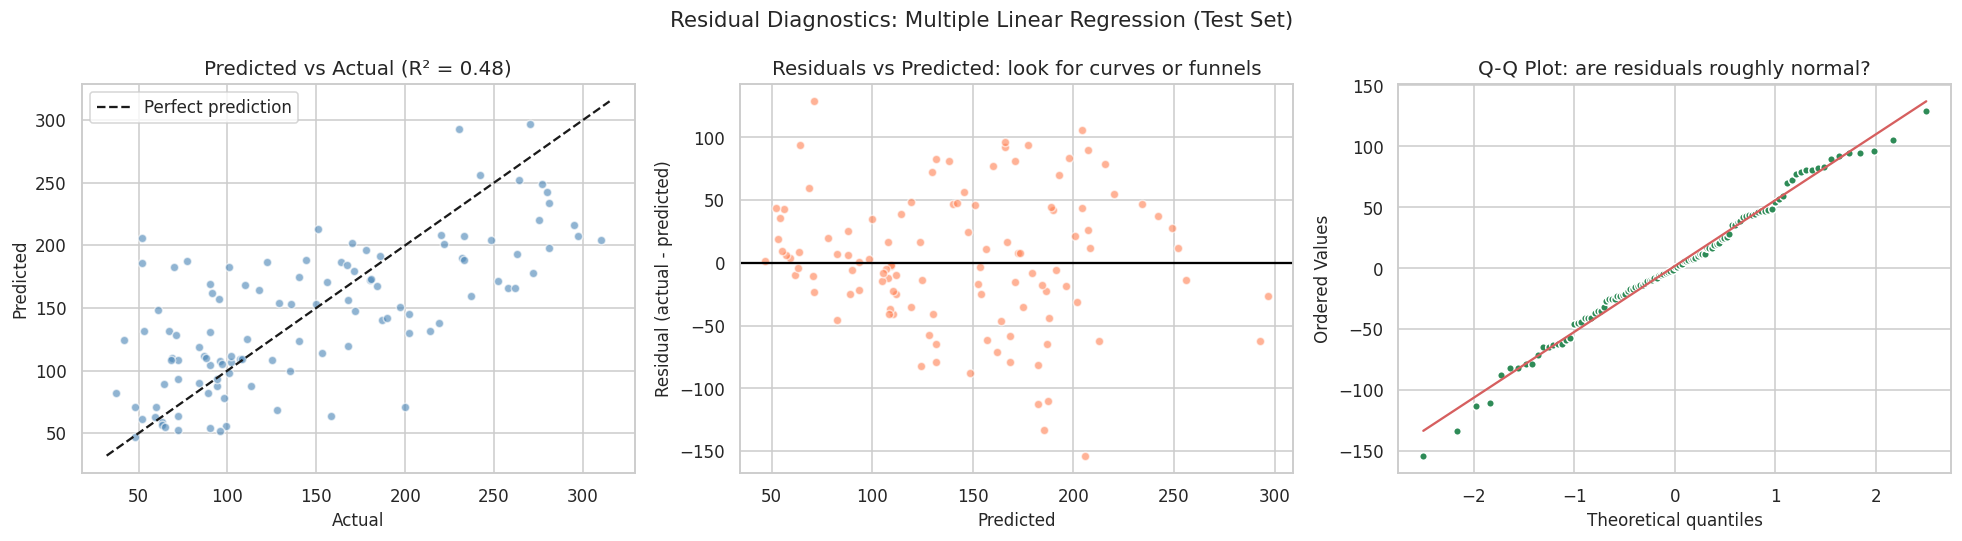

Mean residual: 1.86   Std of residuals: 53.34
How to read: (a) points near the dashed line, (b) a flat shapeless cloud, (c) points near the straight line.


In [ ]:
# ── 2.3  Residual diagnostics ────────────────────────────────────────
# Three plots every regression analysis should include.

pred  = ols.predict(X_test)
resid = y_test.values - pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Residual Diagnostics: Multiple Linear Regression (Test Set)", fontsize=14)

# (a) Predicted vs actual
axes[0].scatter(y_test, pred, alpha=0.6, s=30, color="steelblue", edgecolors="white")
lims = [min(y_test.min(), pred.min()) - 5, max(y_test.max(), pred.max()) + 5]
axes[0].plot(lims, lims, "k--", linewidth=1.5, label="Perfect prediction")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Predicted vs Actual (R² = {om['R2']:.2f})")
axes[0].legend()

# (b) Residuals vs predicted
axes[1].scatter(pred, resid, alpha=0.6, s=30, color="coral", edgecolors="white")
axes[1].axhline(0, color="black", linewidth=1.5)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs Predicted: look for curves or funnels")

# (c) Q-Q plot against the normal distribution
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(markerfacecolor="seagreen", markeredgecolor="white", markersize=5)
axes[2].set_title("Q-Q Plot: are residuals roughly normal?")

plt.tight_layout()
plt.show()

print(f"Mean residual: {resid.mean():.2f}   Std of residuals: {resid.std():.2f}")
print("How to read: (a) points near the dashed line, (b) a flat shapeless cloud, (c) points near the straight line.")

### Exercise 1

Using the **synthetic house data** (`X_house`, `y_house`):

1. Split into train (75%) and test (25%) with `random_state=42`.
2. Fit the **mean baseline** and report its test MAE, RMSE, and R².
3. Fit a `StandardScaler` + `LinearRegression` pipeline on all 7 features and report the same three metrics.
4. Plot **predicted vs actual**, **residuals vs predicted**, and **residuals vs `dist_centre_km`** as three panels.
5. Do the residuals show a pattern? Describe the shape in one sentence and name the feature responsible (hint: the generating formula used `exp(-dist/4)`).

```python
# Your code here
```

```
# Your answer here
```

---
## Part 3: Regularisation: Ridge, Lasso & ElasticNet

When features are **correlated** or numerous, OLS coefficients become large and unstable and the model overfits. **Regularisation** adds a penalty on coefficient size to the loss:

| Model | Penalty | Effect on coefficients | Best when |
|---|---|---|---|
| **Ridge (L2)** | $\alpha \sum b_j^2$ | Shrinks all coefficients smoothly toward 0, never exactly 0 | Many correlated features that all matter a bit |
| **Lasso (L1)** | $\alpha \sum \lvert b_j \rvert$ | Shrinks and sets some coefficients **exactly to 0** (built-in feature selection) | You expect only a few features to matter |
| **ElasticNet** | mix of L1 and L2 | Sparse but stable under correlation | Correlated features and you want selection |

- $\alpha$ (called `alpha` in sklearn) controls the strength: $\alpha = 0$ is plain OLS, large $\alpha$ pushes everything to 0.
- **Always scale features first**, otherwise the penalty treats features unfairly depending on their units.
- Choose $\alpha$ by cross-validation: `RidgeCV`, `LassoCV`, `ElasticNetCV` do this for you.

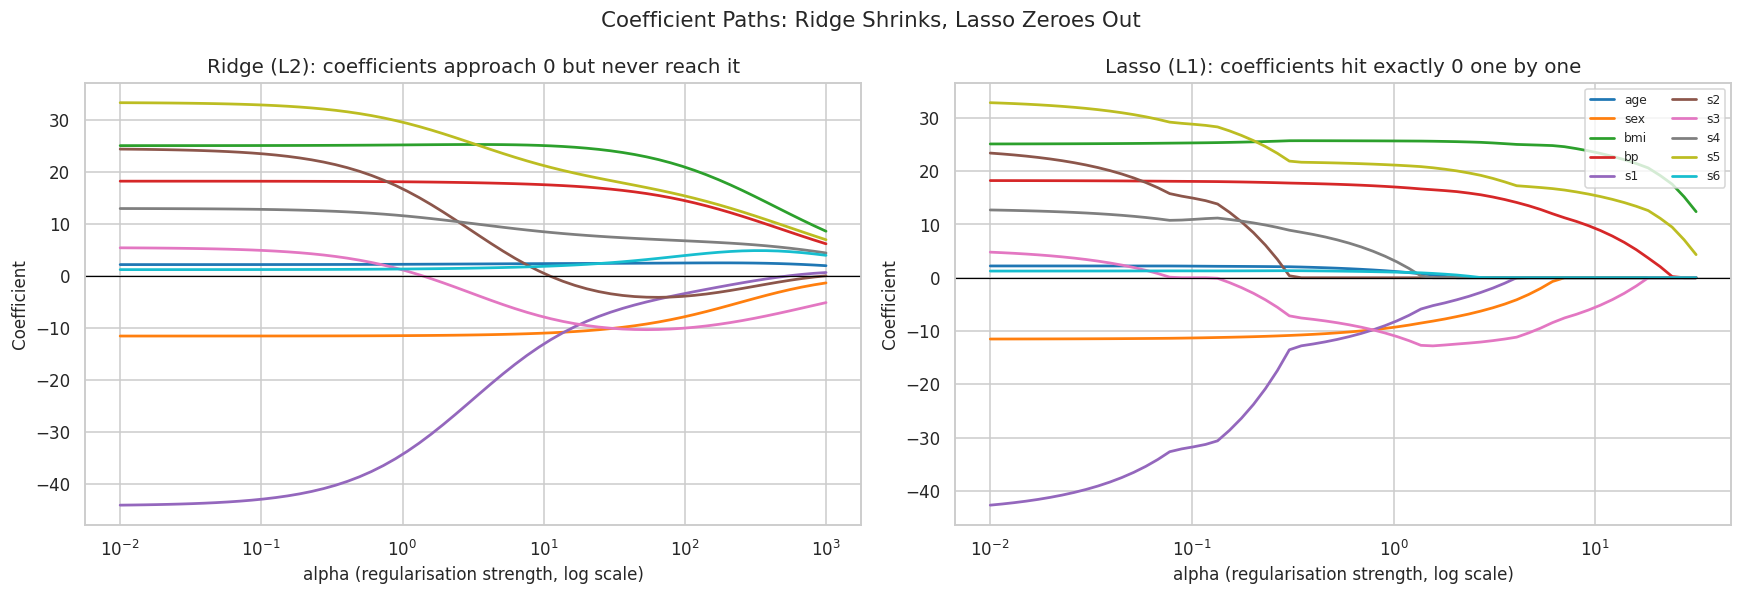

At alpha = 0.60, Lasso has set 1 of 10 coefficients exactly to zero.


In [ ]:
# ── 3.1  Coefficient paths: watch the coefficients shrink ────────────

sc = StandardScaler().fit(X_train)
Xtr_s = sc.transform(X_train)

alphas_r = np.logspace(-2, 3, 60)
coefs_r  = np.array([Ridge(alpha=a).fit(Xtr_s, y_train).coef_ for a in alphas_r])

alphas_l = np.logspace(-2, 1.5, 60)
coefs_l  = np.array([Lasso(alpha=a, max_iter=20000).fit(Xtr_s, y_train).coef_ for a in alphas_l])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Coefficient Paths: Ridge Shrinks, Lasso Zeroes Out", fontsize=14)

pal = sns.color_palette("tab10", X_db.shape[1])
for j, name in enumerate(X_db.columns):
    axes[0].plot(alphas_r, coefs_r[:, j], color=pal[j], linewidth=1.8, label=name)
    axes[1].plot(alphas_l, coefs_l[:, j], color=pal[j], linewidth=1.8, label=name)

for ax, title in zip(axes, ["Ridge (L2): coefficients approach 0 but never reach it",
                            "Lasso (L1): coefficients hit exactly 0 one by one"]):
    ax.set_xscale("log")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("alpha (regularisation strength, log scale)")
    ax.set_ylabel("Coefficient")
    ax.set_title(title)
axes[1].legend(fontsize=8, ncol=2, loc="upper right")

plt.tight_layout()
plt.show()

n_zero_mid = int((np.abs(coefs_l[30]) < 1e-9).sum())
print(f"At alpha = {alphas_l[30]:.2f}, Lasso has set {n_zero_mid} of {X_db.shape[1]} coefficients exactly to zero.")

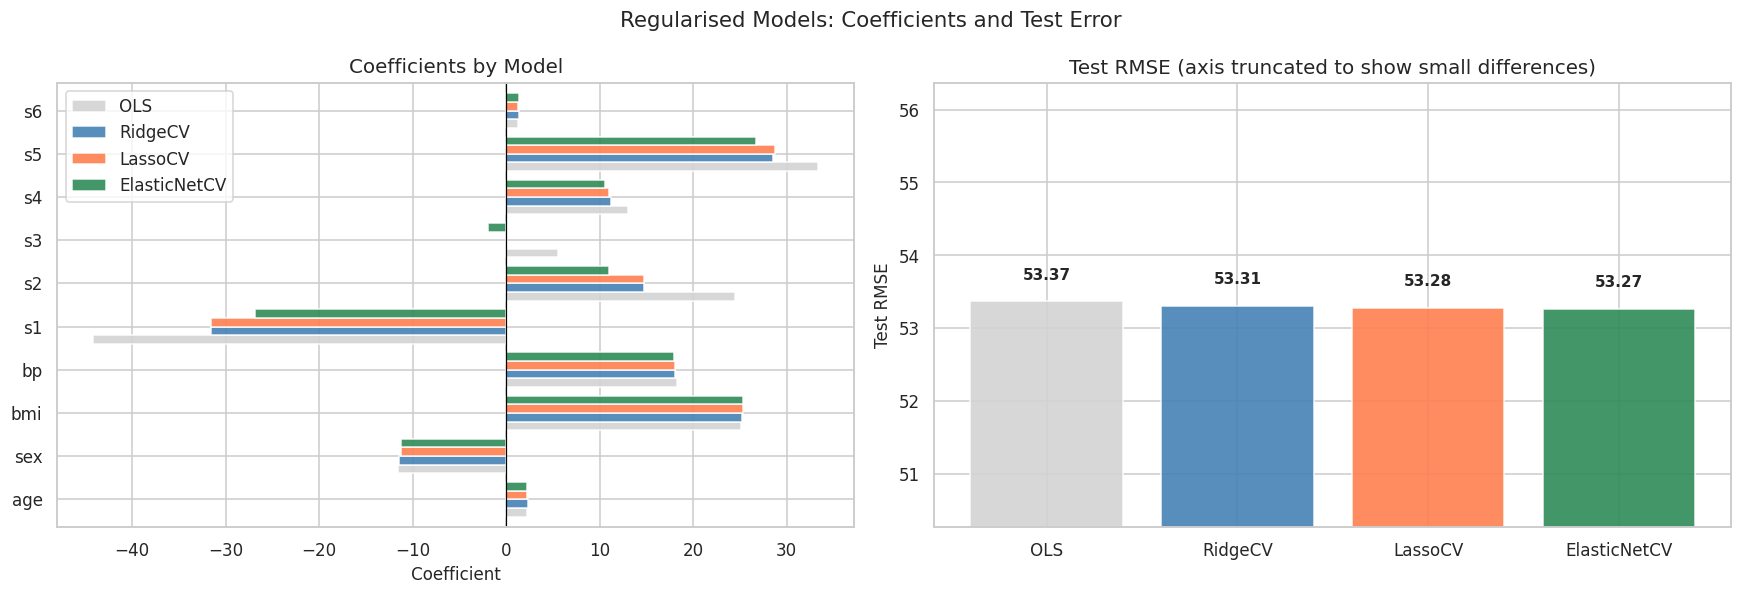

                 MAE    RMSE     R2  alpha
model                                     
OLS           41.549  53.370  0.485    NaN
RidgeCV       41.496  53.307  0.486  1.389
LassoCV       41.481  53.277  0.487  0.106
ElasticNetCV  41.466  53.271  0.487  0.051

Features removed by LassoCV (coefficient exactly 0): ['s3']
The RMSE gains are small here: regularisation mainly buys stability and a simpler model.


In [ ]:
# ── 3.2  Choose alpha by cross-validation and compare ────────────────

reg_models = {
    "OLS":          Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "RidgeCV":      Pipeline([("scaler", StandardScaler()),
                              ("model", RidgeCV(alphas=np.logspace(-2, 3, 50)))]),
    "LassoCV":      Pipeline([("scaler", StandardScaler()),
                              ("model", LassoCV(cv=5, random_state=42, max_iter=20000))]),
    "ElasticNetCV": Pipeline([("scaler", StandardScaler()),
                              ("model", ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=5,
                                                     random_state=42, max_iter=20000))]),
}

rows, coef_table = [], {}
for name, pipe in reg_models.items():
    pipe.fit(X_train, y_train)
    m = reg_metrics(pipe, X_test, y_test)
    m["alpha"] = getattr(pipe.named_steps["model"], "alpha_", np.nan)
    rows.append({"model": name, **m})
    coef_table[name] = pipe.named_steps["model"].coef_
reg_df  = pd.DataFrame(rows).set_index("model")
coef_df = pd.DataFrame(coef_table, index=X_db.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Regularised Models: Coefficients and Test Error", fontsize=14)

coef_df.plot(kind="barh", ax=axes[0], edgecolor="white", alpha=0.9,
             color=["lightgrey", "steelblue", "coral", "seagreen"], width=0.8)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Coefficients by Model")
axes[0].set_xlabel("Coefficient")

axes[1].bar(reg_df.index, reg_df["RMSE"], color=["lightgrey", "steelblue", "coral", "seagreen"],
            edgecolor="white", alpha=0.9)
for i, v in enumerate(reg_df["RMSE"]):
    axes[1].text(i, v + 0.3, f"{v:.2f}", ha="center", fontsize=10, fontweight="bold")
axes[1].set_ylim(reg_df["RMSE"].min() - 3, reg_df["RMSE"].max() + 3)
axes[1].set_ylabel("Test RMSE")
axes[1].set_title("Test RMSE (axis truncated to show small differences)")

plt.tight_layout()
plt.show()

print(reg_df.round(3).to_string())
zeroed = coef_df.index[np.abs(coef_df["LassoCV"]) < 1e-9].tolist()
print(f"\nFeatures removed by LassoCV (coefficient exactly 0): {zeroed}")
print("The RMSE gains are small here: regularisation mainly buys stability and a simpler model.")

### Exercise 2

Using the **synthetic house data** (train/test split from Exercise 1). Remember that `area_sqft` is a near-duplicate of `area_m2` and `random_noise` is unrelated to price.

1. Fit `OLS`, `RidgeCV`, and `LassoCV` (all with a `StandardScaler`).
2. Plot the coefficients of the three models as a grouped horizontal bar chart.
3. What happens to the coefficients of `area_m2` and `area_sqft` under OLS compared with Ridge?
4. Which features did Lasso set to exactly 0? Did it find the useless feature?
5. Report test RMSE for the three models. Which would you choose and why?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 4: Non-linearity, Overfitting & Model Comparison

A straight line cannot follow a curve. Two remedies:

1. **Add polynomial features** ($x, x^2, x^3, \dots$): the model stays linear in its parameters but can bend.
2. **Use a non-linear model** (KNN, trees, ensembles) that learns the shape from data.

The danger: more flexibility means more risk of **overfitting**. A degree-15 polynomial can pass through every training point and still predict new points terribly.

> **Diagnosis:** compare **train error** with **validation error**. If train error keeps falling while test error rises, you have crossed from fitting the signal into fitting the noise.

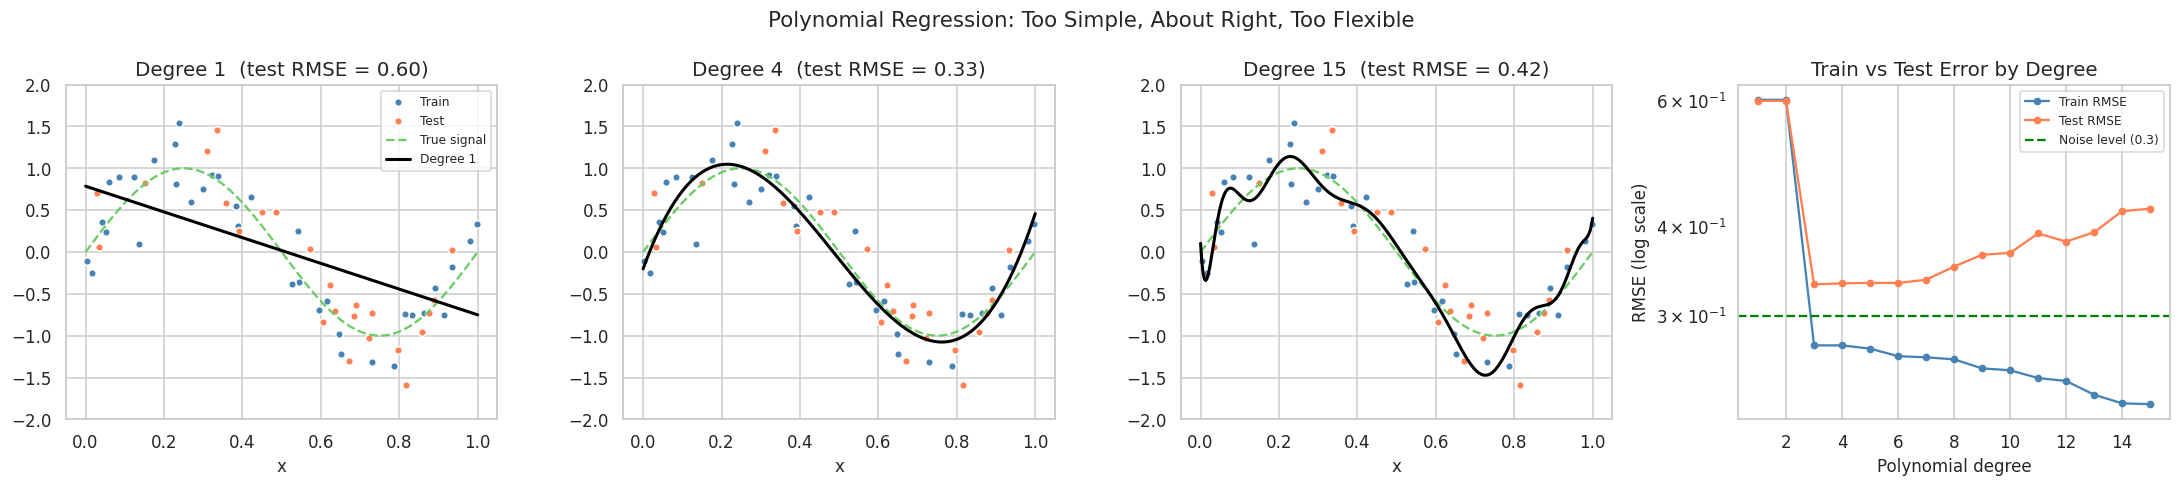

Best degree on this test split: 3  (test RMSE = 0.332)
Train error keeps shrinking with degree; test error eventually turns upward: that is overfitting.


In [ ]:
# ── 4.1  Polynomial degree on a toy curve: underfit, good fit, overfit ─
# True signal: sin(2*pi*x). We add noise and fit polynomials of increasing degree.

rs = np.random.default_rng(0)
x  = np.sort(rs.uniform(0, 1, 60))
y  = np.sin(2 * np.pi * x) + rs.normal(0, 0.3, 60)
x_tr, x_te, y_tr, y_te = train_test_split(x.reshape(-1, 1), y, test_size=0.4, random_state=1)

def poly_model(deg):
    return Pipeline([("poly", PolynomialFeatures(deg, include_bias=False)),
                     ("scaler", StandardScaler()),
                     ("lr", LinearRegression())])

grid_x = np.linspace(0, 1, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
fig.suptitle("Polynomial Regression: Too Simple, About Right, Too Flexible", fontsize=14)

for ax, deg in zip(axes[:3], [1, 4, 15]):
    m = poly_model(deg).fit(x_tr, y_tr)
    ax.scatter(x_tr, y_tr, color="steelblue", s=25, label="Train", edgecolors="white")
    ax.scatter(x_te, y_te, color="coral",     s=25, label="Test",  edgecolors="white")
    ax.plot(grid_x, np.sin(2 * np.pi * grid_x), "g--", linewidth=1.5, label="True signal")
    ax.plot(grid_x, m.predict(grid_x), color="black", linewidth=2, label=f"Degree {deg}")
    ax.set_ylim(-2, 2)
    rm_te = np.sqrt(mean_squared_error(y_te, m.predict(x_te)))
    ax.set_title(f"Degree {deg}  (test RMSE = {rm_te:.2f})")
    ax.set_xlabel("x")
axes[0].legend(fontsize=8)

degrees = np.arange(1, 16)
tr_err, te_err = [], []
for d in degrees:
    m = poly_model(d).fit(x_tr, y_tr)
    tr_err.append(np.sqrt(mean_squared_error(y_tr, m.predict(x_tr))))
    te_err.append(np.sqrt(mean_squared_error(y_te, m.predict(x_te))))

axes[3].plot(degrees, tr_err, "o-", color="steelblue", label="Train RMSE", markersize=4)
axes[3].plot(degrees, te_err, "o-", color="coral",     label="Test RMSE",  markersize=4)
axes[3].axhline(0.3, color="green", linestyle="--", label="Noise level (0.3)")
axes[3].set_yscale("log")
axes[3].set_xlabel("Polynomial degree")
axes[3].set_ylabel("RMSE (log scale)")
axes[3].set_title("Train vs Test Error by Degree")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

best_deg = degrees[int(np.argmin(te_err))]
print(f"Best degree on this test split: {best_deg}  (test RMSE = {min(te_err):.3f})")
print("Train error keeps shrinking with degree; test error eventually turns upward: that is overfitting.")

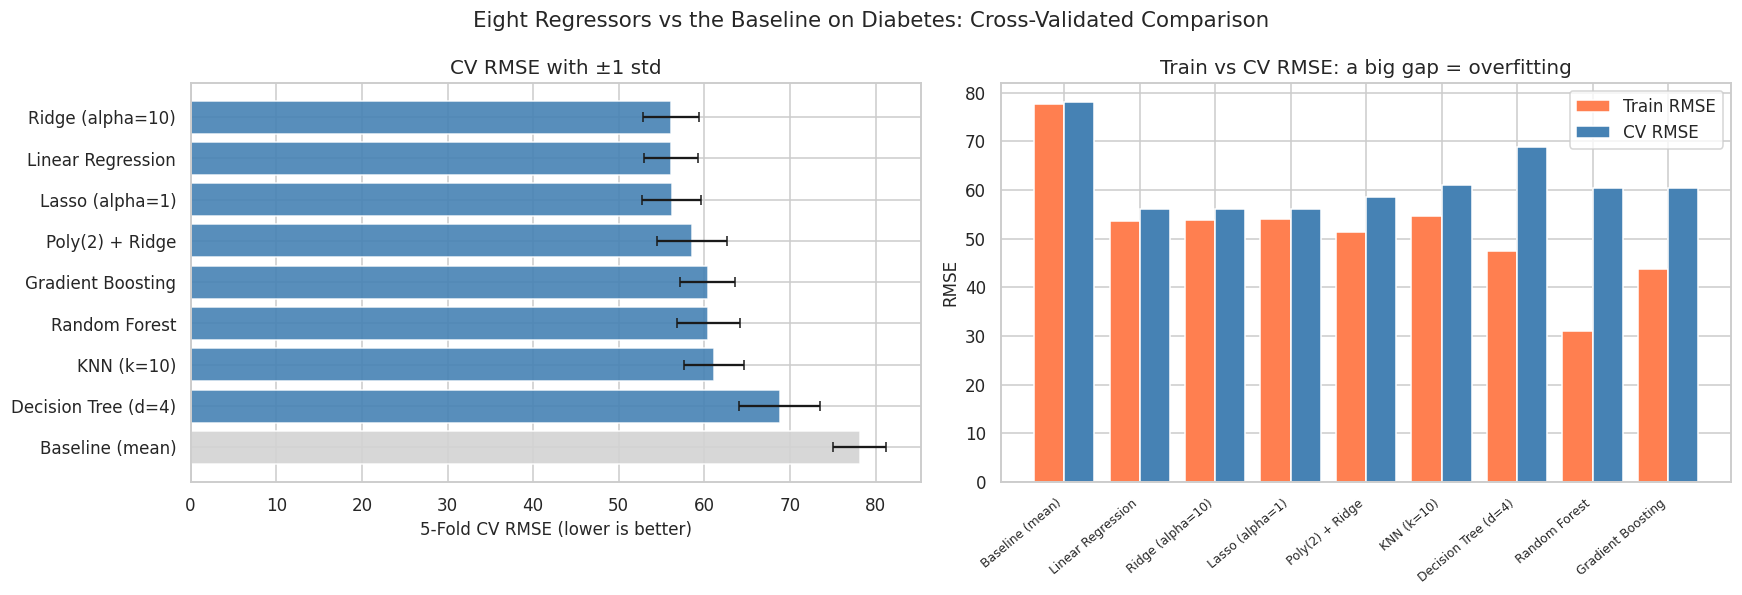

                     train_rmse  cv_rmse  cv_std  cv_r2  test_rmse
model                                                             
Baseline (mean)           77.69    78.14    3.12  -0.04      74.88
Linear Regression         53.66    56.12    3.13   0.46      53.37
Ridge (alpha=10)          53.87    56.11    3.30   0.46      53.20
Lasso (alpha=1)           53.97    56.17    3.45   0.46      52.77
Poly(2) + Ridge           51.34    58.53    4.09   0.42      52.50
KNN (k=10)                54.64    61.08    3.50   0.36      55.15
Decision Tree (d=4)       47.35    68.79    4.74   0.19      59.65
Random Forest             30.97    60.46    3.69   0.37      53.34
Gradient Boosting         43.81    60.39    3.20   0.38      53.89

Best by CV RMSE: Ridge (alpha=10)
On noisy data like this, flexible models often do NOT beat a well-regularised linear model.
Complexity must earn its place through cross-validation, not through train error.


In [ ]:
# ── 4.2  Nine models (incl. baseline) compared with 5-fold CV on diabetes ─

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models_reg = {
    "Baseline (mean)":     DummyRegressor(strategy="mean"),
    "Linear Regression":   Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
    "Ridge (alpha=10)":    Pipeline([("s", StandardScaler()), ("m", Ridge(alpha=10))]),
    "Lasso (alpha=1)":     Pipeline([("s", StandardScaler()), ("m", Lasso(alpha=1, max_iter=20000))]),
    "Poly(2) + Ridge":     Pipeline([("s", StandardScaler()), ("p", PolynomialFeatures(2, include_bias=False)),
                                     ("m", Ridge(alpha=100))]),
    "KNN (k=10)":          Pipeline([("s", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=10))]),
    "Decision Tree (d=4)": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42),
    "Gradient Boosting":   GradientBoostingRegressor(n_estimators=100, learning_rate=0.05,
                                                     max_depth=2, random_state=42),
}

rows = []
for name, m in models_reg.items():
    r = cross_validate(m, X_train, y_train, cv=kf,
                       scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
                       return_train_score=True)
    m.fit(X_train, y_train)
    rows.append({"model": name,
                 "train_rmse": -r["train_rmse"].mean(),
                 "cv_rmse":    -r["test_rmse"].mean(),
                 "cv_std":      r["test_rmse"].std(),
                 "cv_r2":       r["test_r2"].mean(),
                 "test_rmse":   reg_metrics(m, X_test, y_test)["RMSE"]})
cv_res = pd.DataFrame(rows).set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Eight Regressors vs the Baseline on Diabetes: Cross-Validated Comparison", fontsize=14)

order = cv_res.sort_values("cv_rmse", ascending=False)
axes[0].barh(order.index, order["cv_rmse"], xerr=order["cv_std"], capsize=3,
             color=["lightgrey" if "Baseline" in n else "steelblue" for n in order.index],
             edgecolor="white", alpha=0.9)
axes[0].set_xlabel("5-Fold CV RMSE (lower is better)")
axes[0].set_title("CV RMSE with ±1 std")

x_pos = np.arange(len(cv_res))
axes[1].bar(x_pos - 0.2, cv_res["train_rmse"], 0.4, label="Train RMSE", color="coral", edgecolor="white")
axes[1].bar(x_pos + 0.2, cv_res["cv_rmse"],    0.4, label="CV RMSE",    color="steelblue", edgecolor="white")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cv_res.index, rotation=40, ha="right", fontsize=8)
axes[1].set_ylabel("RMSE")
axes[1].set_title("Train vs CV RMSE: a big gap = overfitting")
axes[1].legend()

plt.tight_layout()
plt.show()

print(cv_res.round(2).to_string())
best_name = cv_res.drop("Baseline (mean)")["cv_rmse"].idxmin()
print(f"\nBest by CV RMSE: {best_name}")
print("On noisy data like this, flexible models often do NOT beat a well-regularised linear model.")
print("Complexity must earn its place through cross-validation, not through train error.")

### Exercise 3

Generate a toy dataset that mimics the distance effect in the house data:

```python
r = np.random.default_rng(3)
x = np.sort(r.uniform(0, 15, 80))
y = 140 * np.exp(-x / 4) + r.normal(0, 12, 80)      # true signal + noise (std 12)
```

1. Split 50/50 into train and test (`random_state=0`).
2. Fit polynomial regressions of degree 1 to 12 (`PolynomialFeatures` + `StandardScaler` + `LinearRegression`).
3. Plot **train RMSE** and **test RMSE** against degree, and draw the noise level (12) as a dashed line.
4. Which degree gives the lowest test RMSE? Does train RMSE agree?
5. Explain in one sentence why the straight line (degree 1) underfits, and in one sentence why very high degrees overfit.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 5: Interpreting Models: Permutation Importance

Coefficients explain **linear** models. For non-linear models (forests, boosting) we need a model-agnostic tool.

**Permutation importance:** shuffle one feature's values in the **test set**, and measure how much the score drops. A large drop means the model relied on that feature.

| Property | Permutation importance | Tree `feature_importances_` |
|---|---|---|
| Works with any model | Yes | Trees only |
| Computed on | Held-out data (honest) | Training data (can be biased) |
| Handles correlated features | Splits credit between them | Splits credit between them |

> **Caveat:** if two features are highly correlated, shuffling one barely hurts the model because the other still carries the information. Both can look unimportant even if the pair is essential.

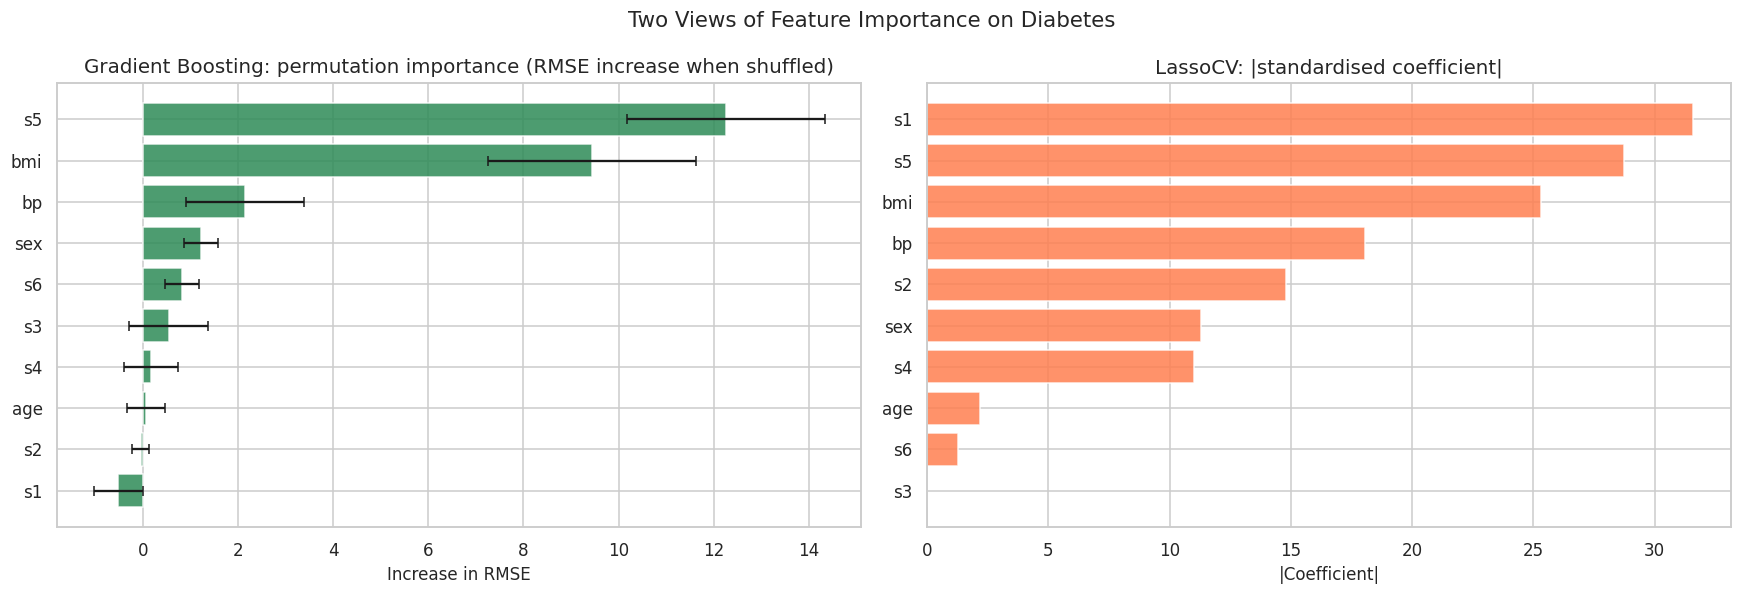

Top 3 by permutation importance (boosting): ['s5', 'bmi', 'bp']
Top 3 by Lasso coefficient size:            ['s1', 's5', 'bmi']
Overlap in the top features is reassuring. Disagreement is worth a closer look: it is often caused by
correlated features (here s1 and s2), which linear coefficients and permutation scores treat differently.


In [ ]:
# ── 5.1  Permutation importance vs linear coefficients ───────────────

gb = models_reg["Gradient Boosting"]       # already fitted on the training set in 4.2
perm = permutation_importance(gb, X_test, y_test, n_repeats=30, random_state=42,
                              scoring="neg_root_mean_squared_error")
perm_df = pd.DataFrame({"feature": X_db.columns,
                        "importance": perm.importances_mean,
                        "std": perm.importances_std}).sort_values("importance")

lasso_coef = pd.Series(reg_models["LassoCV"].named_steps["model"].coef_, index=X_db.columns)
lasso_abs  = lasso_coef.abs().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Two Views of Feature Importance on Diabetes", fontsize=14)

axes[0].barh(perm_df["feature"], perm_df["importance"], xerr=perm_df["std"],
             color="seagreen", edgecolor="white", alpha=0.85, capsize=3)
axes[0].set_title("Gradient Boosting: permutation importance (RMSE increase when shuffled)")
axes[0].set_xlabel("Increase in RMSE")

axes[1].barh(lasso_abs.index, lasso_abs.values, color="coral", edgecolor="white", alpha=0.85)
axes[1].set_title("LassoCV: |standardised coefficient|")
axes[1].set_xlabel("|Coefficient|")

plt.tight_layout()
plt.show()

top_perm  = perm_df["feature"].tail(3).tolist()[::-1]
top_lasso = lasso_abs.index[-3:].tolist()[::-1]
print(f"Top 3 by permutation importance (boosting): {top_perm}")
print(f"Top 3 by Lasso coefficient size:            {top_lasso}")
print("Overlap in the top features is reassuring. Disagreement is worth a closer look: it is often caused by")
print("correlated features (here s1 and s2), which linear coefficients and permutation scores treat differently.")

---
## Part 6: Tuning a Pipeline with GridSearchCV

We can tune **preprocessing and model together**. Here the grid covers the polynomial **degree** and the Ridge **alpha**. The pipeline guarantees that scaling and feature expansion are refit inside every CV fold, so there is no leakage.

> **Interaction:** higher polynomial degree needs stronger regularisation. Tuning degree and alpha **jointly** captures this; tuning them one at a time does not.

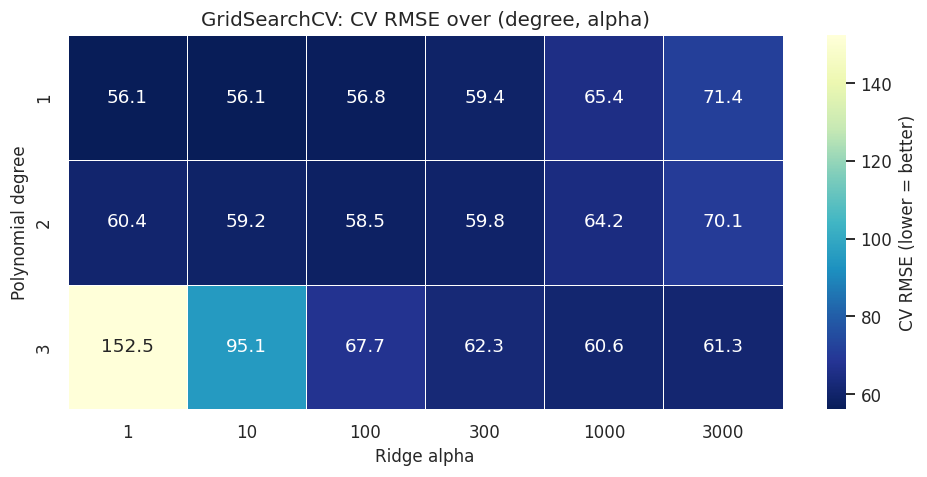

Best parameters: {'poly__degree': 1, 'ridge__alpha': 1}   (CV RMSE = 56.07)
Tuned pipeline on the test set:  RMSE = 53.32   R2 = 0.486
Plain OLS on the test set:       RMSE = 53.37   R2 = 0.485

If degree 1 wins, the data does not justify extra flexibility: tuning can also tell you to stay simple.


In [ ]:
# ── 6.1  Joint grid over polynomial degree and Ridge alpha ───────────

pipe = Pipeline([("scaler", StandardScaler()),
                 ("poly",   PolynomialFeatures(include_bias=False)),
                 ("ridge",  Ridge())])

param_grid = {
    "poly__degree": [1, 2, 3],
    "ridge__alpha": [1, 10, 100, 300, 1000, 3000],
}

gs = GridSearchCV(pipe, param_grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)

res  = pd.DataFrame(gs.cv_results_)
heat = (-res.pivot(index="param_poly__degree", columns="param_ridge__alpha",
                   values="mean_test_score")).astype(float)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu_r", linewidths=0.5, ax=ax,
            cbar_kws={"label": "CV RMSE (lower = better)"})
ax.set_title("GridSearchCV: CV RMSE over (degree, alpha)")
ax.set_xlabel("Ridge alpha")
ax.set_ylabel("Polynomial degree")
plt.tight_layout()
plt.show()

tuned = gs.best_estimator_
tm = reg_metrics(tuned, X_test, y_test)
print(f"Best parameters: {gs.best_params_}   (CV RMSE = {-gs.best_score_:.2f})")
print(f"Tuned pipeline on the test set:  RMSE = {tm['RMSE']:.2f}   R2 = {tm['R2']:.3f}")
print(f"Plain OLS on the test set:       RMSE = {om['RMSE']:.2f}   R2 = {om['R2']:.3f}")
print("\nIf degree 1 wins, the data does not justify extra flexibility: tuning can also tell you to stay simple.")

### Exercise 4

Using the **synthetic house data** (train/test split from Exercise 1):

1. Build **four pipelines**:
   - `StandardScaler` + `LinearRegression`
   - `StandardScaler` + `Ridge(alpha=10)`
   - `StandardScaler` + `PolynomialFeatures(2)` + `Ridge(alpha=10)`
   - `RandomForestRegressor(n_estimators=200)`
2. Evaluate each with **5-fold CV** on the training set (RMSE) and once on the test set.
3. Plot the CV RMSE as a bar chart with error bars (mean ± std), with the mean-baseline RMSE as a dashed line.
4. Which pipeline wins? Compare with the diabetes result in 4.2: does non-linearity help more here, and which kind of non-linearity works best?
5. Run `GridSearchCV` over `RandomForestRegressor` (`max_depth` in `[3, 5, 8, None]`, `min_samples_leaf` in `[1, 3, 5]`) and report whether tuning improves the test RMSE.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 7: The Full Regression Dashboard: Storytelling

A regression report must answer four questions: **what are we predicting, which drivers matter, how good is the final model, and how does it compare to the alternatives?**

**Storytelling checklist:**
1. **Target:** what does the outcome look like, and what error does the baseline make?
2. **Drivers:** which features carry the effect, and does regularisation agree?
3. **Fit:** how close are predictions to reality for the chosen model?
4. **Comparison:** does extra complexity buy a real improvement over the baseline and over simple models?

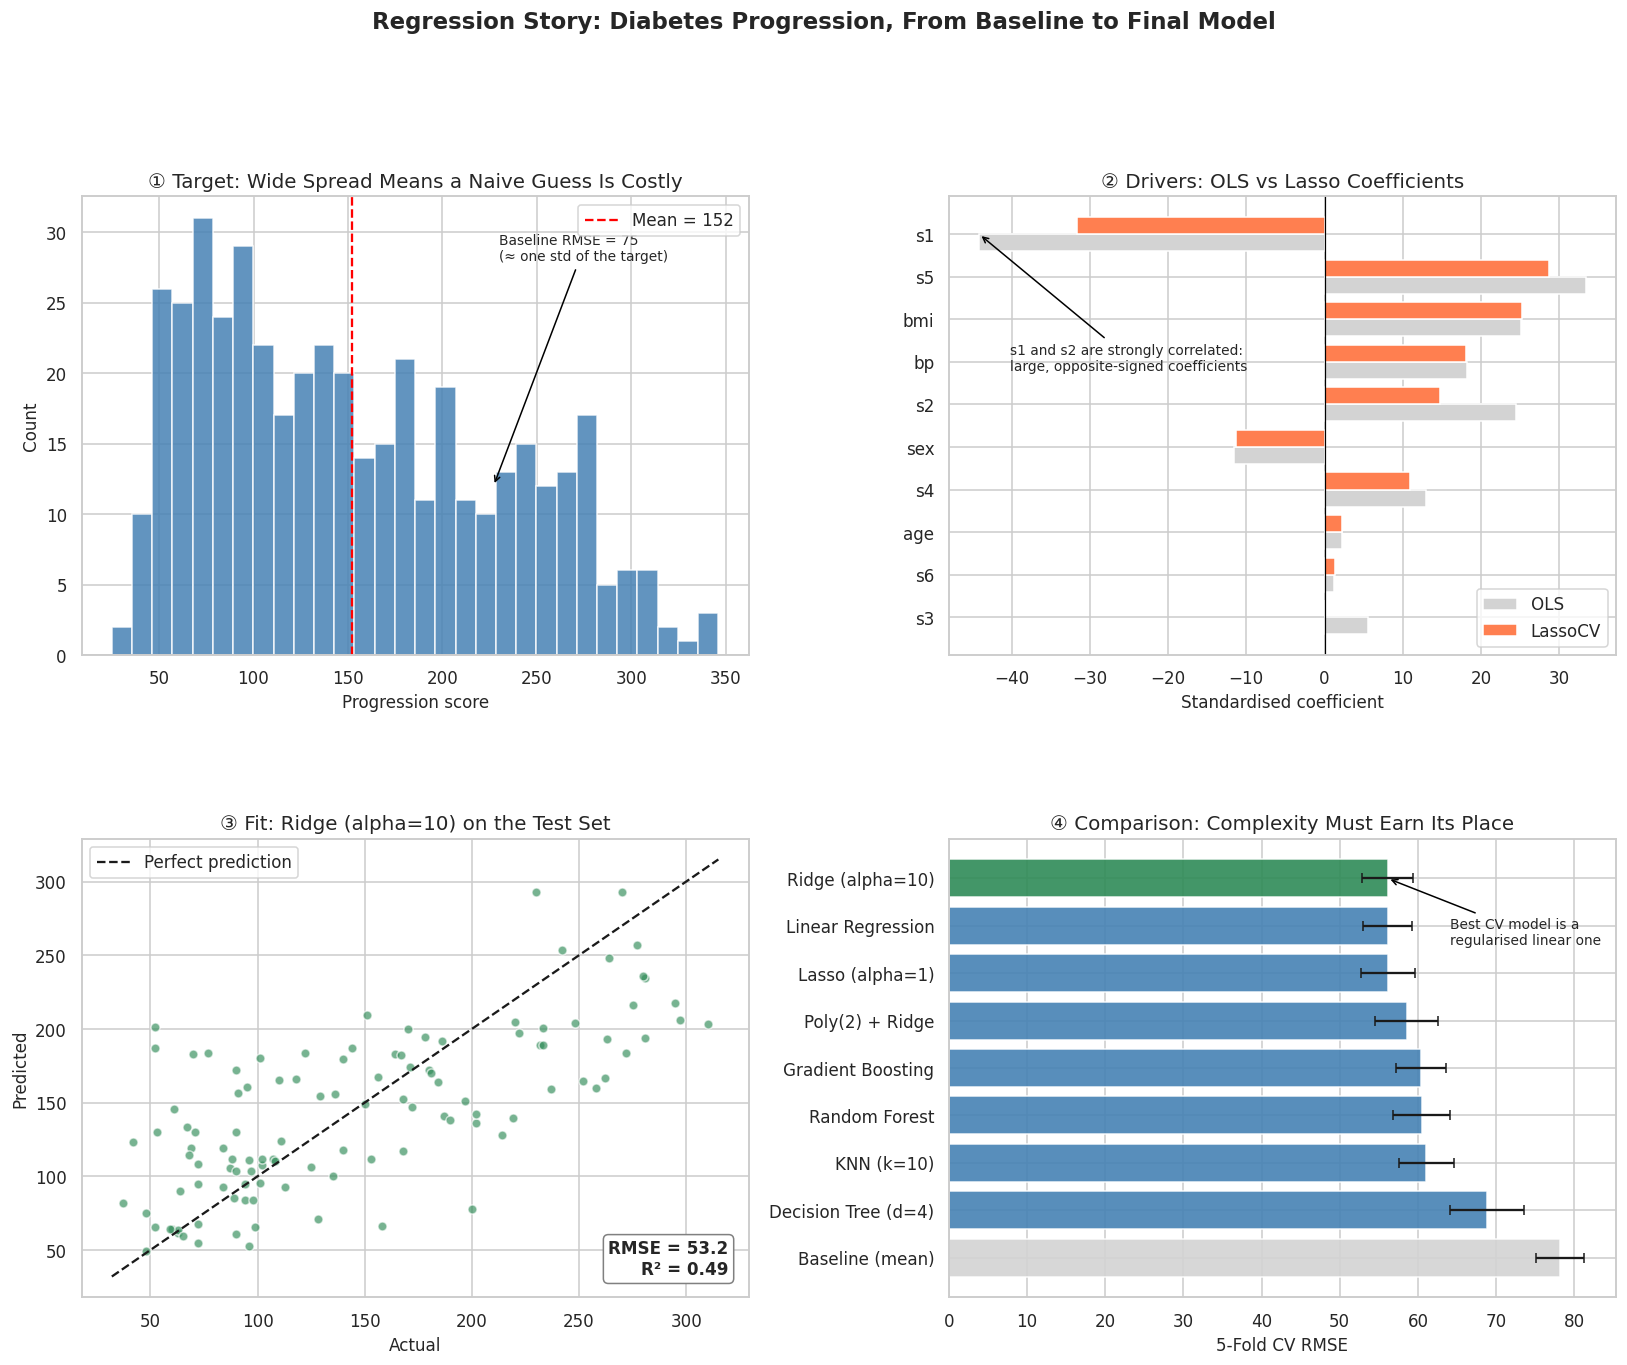

Dashboard saved as regression_dashboard.png


In [ ]:
# ── 7.1  The Regression Dashboard ────────────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.suptitle("Regression Story: Diabetes Progression, From Baseline to Final Model",
             fontsize=15, fontweight="bold", y=1.01)

gs_ = gridspec.GridSpec(2, 2, hspace=0.40, wspace=0.30)

# ── Panel 1: target and baseline error ────────────────────────────────
ax1 = fig.add_subplot(gs_[0, 0])
ax1.hist(y_db, bins=30, color="steelblue", edgecolor="white", alpha=0.85)
ax1.axvline(y_db.mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean = {y_db.mean():.0f}")
ax1.set_xlabel("Progression score")
ax1.set_ylabel("Count")
ax1.set_title("① Target: Wide Spread Means a Naive Guess Is Costly")
ax1.legend()
ax1.annotate(f"Baseline RMSE = {base_m['RMSE']:.0f}\n(≈ one std of the target)",
             xy=(y_db.mean() + base_m["RMSE"], 12), xytext=(230, 28),
             fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 2: drivers (OLS vs Lasso) ───────────────────────────────────
ax2 = fig.add_subplot(gs_[0, 1])
dr = coef_df[["OLS", "LassoCV"]].loc[coef_df["LassoCV"].abs().sort_values().index]
yy = np.arange(len(dr))
ax2.barh(yy - 0.2, dr["OLS"],     0.4, color="lightgrey", edgecolor="white", label="OLS")
ax2.barh(yy + 0.2, dr["LassoCV"], 0.4, color="coral",     edgecolor="white", label="LassoCV")
ax2.set_yticks(yy)
ax2.set_yticklabels(dr.index)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Standardised coefficient")
ax2.set_title("② Drivers: OLS vs Lasso Coefficients")
ax2.legend(loc="lower right")
s1_pos = list(dr.index).index("s1")
ax2.annotate("s1 and s2 are strongly correlated:\nlarge, opposite-signed coefficients", xy=(dr.loc["s1", "OLS"], s1_pos),
             xytext=(dr.loc["s1", "OLS"] + 4, s1_pos - 3.2), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 3: predicted vs actual for the best CV model ────────────────
ax3 = fig.add_subplot(gs_[1, 0])
best_model = models_reg[best_name]
bp = best_model.predict(X_test)
bm = reg_metrics(best_model, X_test, y_test)
ax3.scatter(y_test, bp, alpha=0.65, s=35, color="seagreen", edgecolors="white")
lims = [min(y_test.min(), bp.min()) - 5, max(y_test.max(), bp.max()) + 5]
ax3.plot(lims, lims, "k--", linewidth=1.5, label="Perfect prediction")
ax3.set_xlabel("Actual")
ax3.set_ylabel("Predicted")
ax3.set_title(f"③ Fit: {best_name} on the Test Set")
ax3.legend(loc="upper left")
ax3.text(0.97, 0.05, f"RMSE = {bm['RMSE']:.1f}\nR² = {bm['R2']:.2f}", transform=ax3.transAxes,
         ha="right", fontsize=11, fontweight="bold",
         bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey"))

# ── Panel 4: model comparison ─────────────────────────────────────────
ax4 = fig.add_subplot(gs_[1, 1])
o = cv_res.sort_values("cv_rmse", ascending=False)
ax4.barh(o.index, o["cv_rmse"], xerr=o["cv_std"], capsize=3,
         color=["lightgrey" if "Baseline" in n else ("seagreen" if n == best_name else "steelblue") for n in o.index],
         edgecolor="white", alpha=0.9)
ax4.set_xlabel("5-Fold CV RMSE")
ax4.set_title("④ Comparison: Complexity Must Earn Its Place")
ax4.annotate("Best CV model is a\nregularised linear one", xy=(o.loc[best_name, "cv_rmse"], len(o) - 1),
             xytext=(o["cv_rmse"].max() * 0.82, 6.6), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="black"))

plt.tight_layout()
plt.savefig("regression_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as regression_dashboard.png")

### Exercise 5: Final Challenge

Using the **synthetic house data** (`X_house`, `y_house`), build your own **Regression Dashboard** that tells the full modelling story.

1. **Panel 1 (Target):** histogram of `price_k_eur` with the mean marked and the baseline RMSE annotated.
2. **Panel 2 (Comparison):** horizontal bar chart of 5-fold CV RMSE for at least four models, including the mean baseline.
3. **Panel 3 (Fit):** predicted vs actual scatter for your best model, with the perfect-prediction line and R² shown.
4. **Panel 4 (Drivers):** permutation importance of your best model on the test set, horizontal bar chart.
5. Combine all four panels in a `2×2` `GridSpec` figure with a headline title.
6. Add **at least one annotation** on any panel highlighting the most important insight.
7. Write 3-4 sentences below the dashboard summarising:
   - How much better is your best model than the baseline, in thousand EUR?
   - Which features drive the price, and is `random_noise` correctly ranked last?
   - Did the non-linear distance effect require a non-linear model?
   - Which model would you deploy and why?

```python
# Your code here
```

```
# Your answer here
```

---
## Summary

| Concept | What it solves | Key tools |
|---|---|---|
| **Baseline** | A floor every model must beat | `DummyRegressor(strategy="mean")` |
| **MAE / RMSE / R²** | Error in target units, and variance explained | `mean_absolute_error`, `mean_squared_error`, `r2_score` |
| **Linear regression** | Interpretable linear effects | `LinearRegression`, coefficients on scaled data |
| **Residual diagnostics** | Detect curves, funnels, non-normal errors | Predicted-vs-actual, residual plot, Q-Q plot |
| **Ridge (L2)** | Stabilise correlated features | `Ridge`, `RidgeCV` |
| **Lasso (L1)** | Automatic feature selection | `Lasso`, `LassoCV` |
| **ElasticNet** | Sparse and stable | `ElasticNet`, `ElasticNetCV` |
| **Polynomial features** | Let linear models bend | `PolynomialFeatures` |
| **Non-linear models** | Learn shapes from data | `KNeighborsRegressor`, `RandomForestRegressor`, `GradientBoostingRegressor` |
| **Permutation importance** | Model-agnostic interpretation | `sklearn.inspection.permutation_importance` |
| **Pipeline + GridSearchCV** | Leak-proof joint tuning | `Pipeline`, `GridSearchCV` |

---
**The regression decision loop:**
1. Split first and fit the mean baseline  
2. Fit a linear model on scaled features and read the residual plots  
3. If residuals show a pattern, add non-linearity (polynomial features or a tree ensemble)  
4. If coefficients are unstable or numerous, add regularisation and choose alpha by CV  
5. Compare candidates with cross-validated RMSE, in the units of the target  
6. Interpret the winner (coefficients or permutation importance) and report test error once